# TSP by clustering – asymmetric distances

A route through **all 10 Tallinn locations** is too large for QAOA in one piece (9 customers → 81 qubits).
We split it into small sub-problems, solve each with QAOA and glue the routes together:

1. **Clustering.** The customers (all locations **except the depot S0**) are split into clusters with KMeans.
2. **Representatives.** From every cluster we take the location **closest to the depot**.
3. **Central graph.** Depot S0 + one representative per cluster. Its TSP route decides the order of the clusters;
   the vehicle starts and ends here, at S0.
4. **Cluster graphs.** Every cluster is a separate TSP whose local depot is its representative: the vehicle arrives at the
   representative, drives a **closed loop** through the cluster and returns to the representative.
5. **Final route** = central route with the cluster loops inserted at the representatives.

```
           ┌── loop A ──┐          ┌── loop B ──┐
  S0 ──→ rep A ←──────────┘ ──→ rep B ←─────────┘ ──→ rep C … ──→ S0
```

Every sub-problem is solved the same way (library `tsp_library.ipynb`): **train on the ideal Estimator**
(`train_with_estimator`), **sample on the Sampler** (`run_sampler`) and take the **shortest valid sampled route**.
All distances are **asymmetric** (driving i → j can differ from j → i, one-way streets).

## 0. Load the library

Executes only the library part of `tsp_library.ipynb` (everything before its own experiments),
so loading takes seconds and does not re-run the examples there.

In [1]:
import json

LIBRARY = "tsp_library.ipynb"
STOP_AT = ("# Implementing the first approach", "## 9. example")   # library code ends before these headings

for _cell in json.load(open(LIBRARY, encoding="utf-8"))["cells"]:
    _src = "".join(_cell["source"])
    if _cell["cell_type"] == "markdown" and _src.lstrip().startswith(STOP_AT):
        break
    if _cell["cell_type"] == "code":
        exec(_src, globals())

from sklearn.cluster import KMeans
print("Library loaded, REPS =", REPS)

Library loaded, REPS = 2


## 1. Configuration

10 locations (index → data file index: name)
  0 → 0: Omniva Pallasti (depot)  [depot]
  1 → 1: Kadriorg President's Office
  2 → 2: Shaurma Kebab Punane
  3 → 3: Kultuurikatel
  4 → 4: Patarei Prison
  5 → 5: 180 Degrees
  6 → 6: TalTech
  7 → 7: Tallinn Zoo
  8 → 8: Nõmme Spordikeskus
  9 → 9: Tallinn Airport


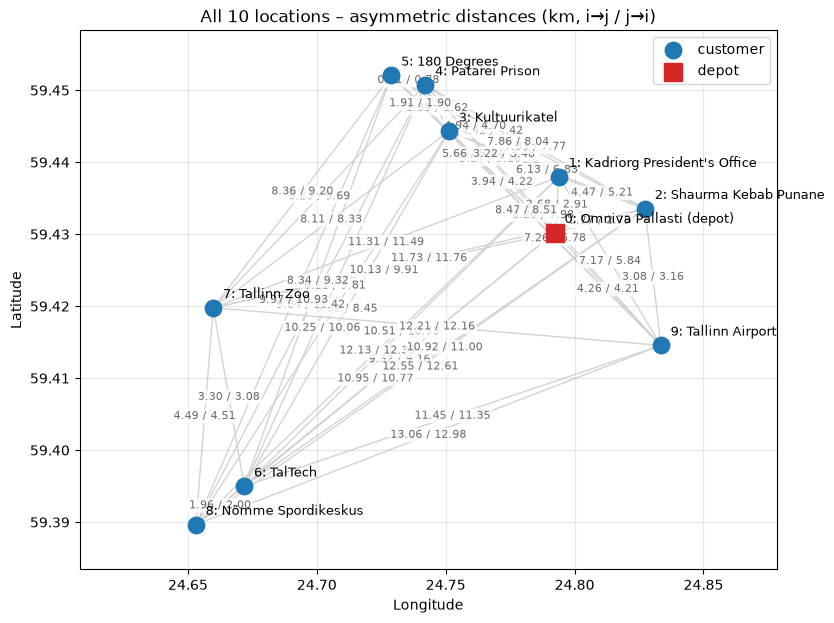

In [2]:
DATA       = "tallinn_osrm_matrix.json"
N_NODES    = 10        # locations 0..9 (location 10 in the file is only a copy of the depot)
N_CLUSTERS = 3
SYMMETRIC  = False     # asymmetric distances everywhere
PENALTY    = 20        # starting penalty; raised automatically if the ground state of H is not the optimum
SHOTS      = 10_000
SEED       = 42
MAX_QUBITS = 16        # largest sub-problem we simulate (5 locations = 16 qubits)

inst_all = load_instance(DATA, n=N_NODES, symmetric=SYMMETRIC)
DEPOT = inst_all.ids[0]
print(inst_all)
plot_network(inst_all, title=f"All {inst_all.n} locations – asymmetric distances (km, i→j / j→i)")
plt.show()

## 2. Clustering (without the depot)

KMeans works on the rows of the distance matrix (every location is described by its distances to all locations).
Closeness has no direction, so for clustering we use the **symmetrised** matrix (d + dᵀ)/2;
the TSP sub-problems below use the original asymmetric distances.

In [3]:
def cluster_customers(inst: Instance, n_clusters: int, seed: int = SEED) -> list[list[int]]:
    """Split all locations except the depot (index 0) into clusters. Returns original location ids."""
    sym = (inst.distances + inst.distances.T) / 2
    customers = np.arange(1, inst.n)
    labels = KMeans(n_clusters, n_init=10, random_state=seed).fit_predict(sym[customers])
    return [[inst.ids[i] for i in customers[labels == c]] for c in np.unique(labels)]


def representative(cluster: list[int], inst: Instance) -> int:
    """The location of the cluster closest to the depot (distance depot → location)."""
    return min(cluster, key=lambda i: inst.distances[0, inst.ids.index(i)])


clusters = cluster_customers(inst_all, N_CLUSTERS)
reps = [representative(c, inst_all) for c in clusters]
for k, (c, r) in enumerate(zip(clusters, reps)):
    qubits = (len(c) - 1) ** 2
    print(f"Cluster {k}: {c}  representative {r} ({inst_all.names[inst_all.ids.index(r)]}), "
          f"sub-problem {len(c)} locations → {qubits} qubits")
    if qubits > MAX_QUBITS:
        raise ValueError(f"Cluster {c} is too large for simulation – use more clusters (N_CLUSTERS).")

Cluster 0: [1, 3, 4, 5]  representative 1 (Kadriorg President's Office), sub-problem 4 locations → 9 qubits
Cluster 1: [6, 7, 8]  representative 6 (TalTech), sub-problem 3 locations → 4 qubits
Cluster 2: [2, 9]  representative 2 (Shaurma Kebab Punane), sub-problem 2 locations → 1 qubits


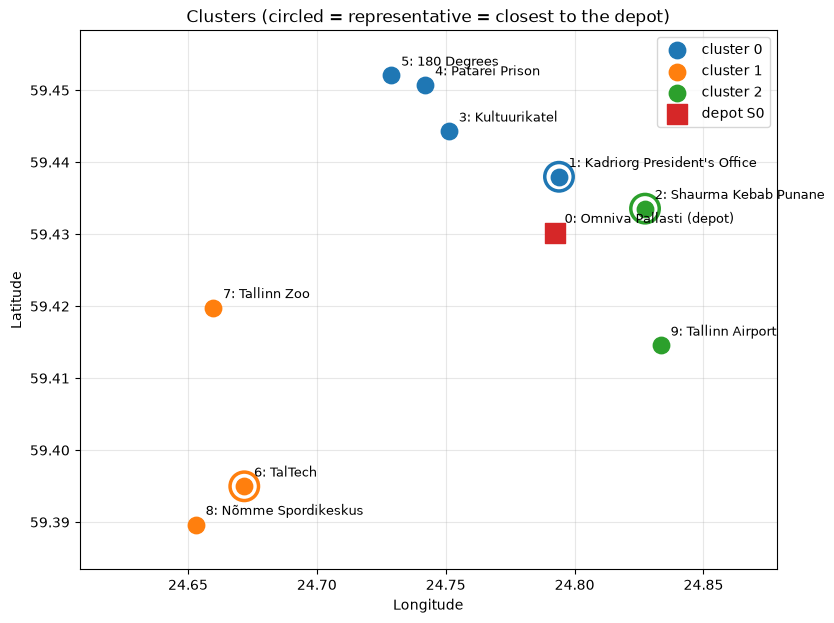

In [4]:
def plot_clusters(inst: Instance, clusters: list[list[int]], reps: list[int]):
    colors = plt.cm.tab10.colors
    fig, ax = plt.subplots(figsize=(9, 7))
    for k, cluster in enumerate(clusters):
        idx = [inst.ids.index(i) for i in cluster]
        ax.scatter(inst.lon[idx], inst.lat[idx], s=140, color=colors[k], label=f"cluster {k}", zorder=3)
        r = inst.ids.index(reps[k])
        ax.scatter(inst.lon[r], inst.lat[r], s=420, facecolors="none", edgecolors=colors[k], linewidths=2.5, zorder=3)
    ax.scatter(inst.lon[0], inst.lat[0], s=200, c="tab:red", marker="s", label="depot S0", zorder=4)
    for i, name in enumerate(inst.names):
        ax.annotate(f"{inst.ids[i]}: {name}", (inst.lon[i], inst.lat[i]), xytext=(7, 7),
                    textcoords="offset points", fontsize=9)
    ax.set_title("Clusters (circled = representative = closest to the depot)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    ax.margins(x=0.25, y=0.1)
    return fig


plot_clusters(inst_all, clusters, reps)
plt.show()

## 3. Solving one sub-problem

`solve_subproblem(nodes)` – the first node is the local depot (S0 for the central graph, the representative for a cluster):

1. builds the Hamiltonian; if its ground state is **not** the classical optimum, the penalty is raised (×1.5) until it is,
2. trains the QAOA angles on the ideal Estimator,
3. samples `SHOTS` shots on the Sampler and takes the **shortest valid sampled route**.

Sub-problems with 1 or 2 locations have only one possible route, so they are not sent to QAOA.

In [5]:
@dataclass
class SubResult:
    label: str
    nodes: list[int]               # original ids, nodes[0] = local depot
    route: tuple[int, ...]         # chosen route in original ids (closed: starts and ends at nodes[0])
    length: float
    optimal_length: float          # classical optimum of this sub-problem
    method: str                    # "QAOA", "trivial" or "classical fallback"
    qubits: int = 0
    penalty: float | None = None
    sampled: SamplingResult | None = None

    @property
    def is_optimal(self) -> bool:
        return bool(np.isclose(self.length, self.optimal_length))


def ground_state_is_optimal(model: IsingModel, distances: np.ndarray, enc: PositionEncoding) -> bool:
    diag = np.real(model.operator.to_matrix(sparse=True).diagonal())
    route = enc.decode(enc.bits_of_index(int(np.argmin(diag))))
    optimal_routes, _ = brute_force(distances, enc.depot)
    return route in optimal_routes


def solve_subproblem(nodes: list[int], label: str) -> SubResult:
    if len(nodes) == 1:
        return SubResult(label, nodes, (nodes[0],), 0.0, 0.0, "trivial")
    inst = load_instance(DATA, nodes=nodes, symmetric=SYMMETRIC)
    to_ids = lambda r: tuple(inst.ids[i] for i in r)
    optimal_routes, optimal_length = brute_force(inst.distances)
    if inst.n == 2:
        return SubResult(label, nodes, to_ids(optimal_routes[0]), optimal_length, optimal_length, "trivial")

    enc = PositionEncoding(inst.n)
    qp = build_qp(inst.distances, enc, name=label)
    penalty = PENALTY
    model = to_hamiltonian(qp, enc, penalty=penalty)
    while not ground_state_is_optimal(model, inst.distances, enc):
        penalty *= 1.5
        model = to_hamiltonian(qp, enc, penalty=penalty)

    ansatz = build_ansatz(model.operator, reps=REPS)
    trained = train_with_estimator(ansatz, model.operator)
    sampled = evaluate_counts(run_sampler(ansatz, trained.params, shots=SHOTS, seed=SEED), inst.distances, enc)
    best = sampled.best_sampled
    if best is None:   # no valid route measured – fall back to the classical optimum so the pipeline can continue
        return SubResult(label, nodes, to_ids(optimal_routes[0]), optimal_length, optimal_length,
                         "classical fallback", enc.num_qubits, penalty, sampled)
    return SubResult(label, nodes, to_ids(best.route), best.length, optimal_length,
                     "QAOA", enc.num_qubits, penalty, sampled)


def report(res: SubResult) -> None:
    print(f"── {res.label}: nodes {res.nodes}  [{res.method}"
          + (f", {res.qubits} qubits, penalty {res.penalty:g}]" if res.qubits else "]"))
    print(f"   route  {' → '.join(map(str, res.route))}   {res.length:.3f} km   "
          f"(classical optimum {res.optimal_length:.3f} km {'✓' if res.is_optimal else '✗'})")
    if res.sampled is not None:
        s = res.sampled
        print(f"   shots on valid routes {s.valid_share:.1%}, on optimal routes {s.optimal_share:.1%}")

## 4. Central graph: depot + one representative per cluster

Its route gives the order in which the clusters are visited.

── central graph: nodes [0, 1, 6, 2]  [QAOA, 9 qubits, penalty 20]
   route  0 → 1 → 6 → 2 → 0   26.931 km   (classical optimum 26.931 km ✓)
   shots on valid routes 15.1%, on optimal routes 2.3%
Cluster order (by representative): [1, 6, 2]


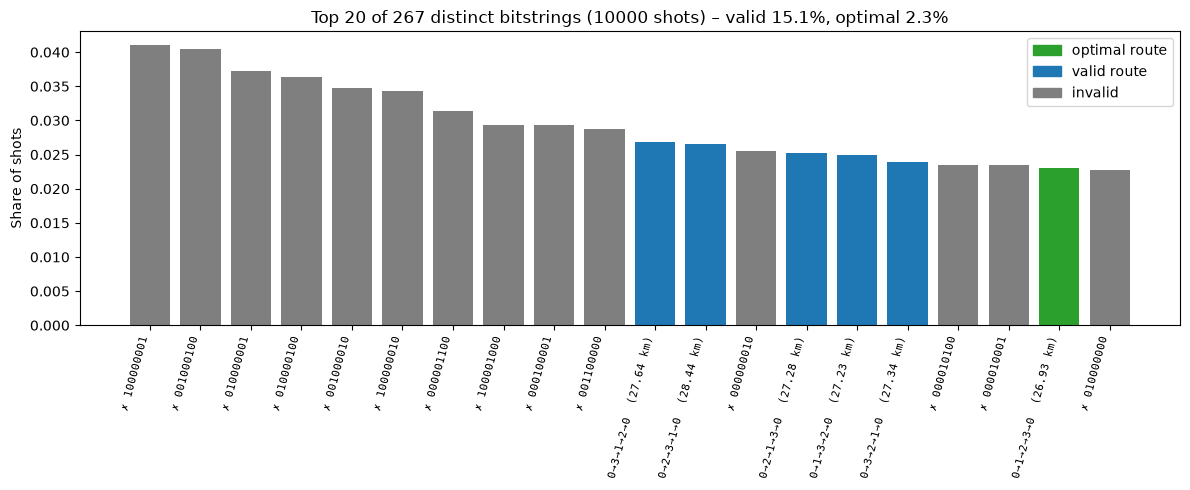

In [6]:
central = solve_subproblem([DEPOT] + reps, "central graph")
report(central)
cluster_order = [r for r in central.route[1:-1]]          # representatives in the order of the central route
print("Cluster order (by representative):", cluster_order)
if central.sampled is not None:
    plot_samples(central.sampled, top=20)
    plt.show()

## 5. Cluster graphs: closed loop from each representative

── cluster of 1: nodes [1, 3, 4, 5]  [QAOA, 9 qubits, penalty 20]
   route  1 → 3 → 4 → 5 → 1   10.109 km   (classical optimum 10.109 km ✓)
   shots on valid routes 31.6%, on optimal routes 5.2%


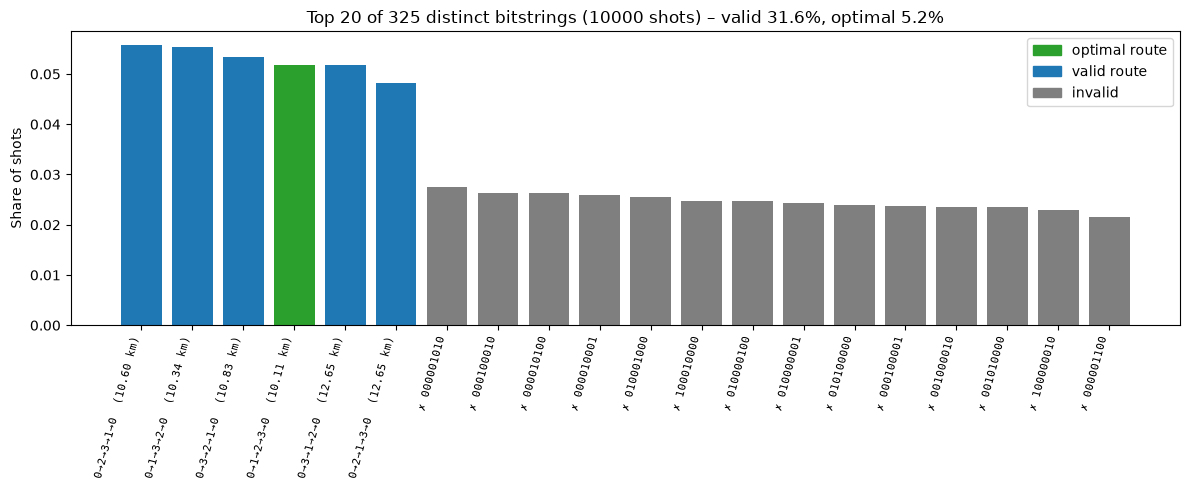

── cluster of 6: nodes [6, 7, 8]  [QAOA, 4 qubits, penalty 20]
   route  6 → 8 → 7 → 6   9.557 km   (classical optimum 9.557 km ✓)
   shots on valid routes 94.2%, on optimal routes 47.4%


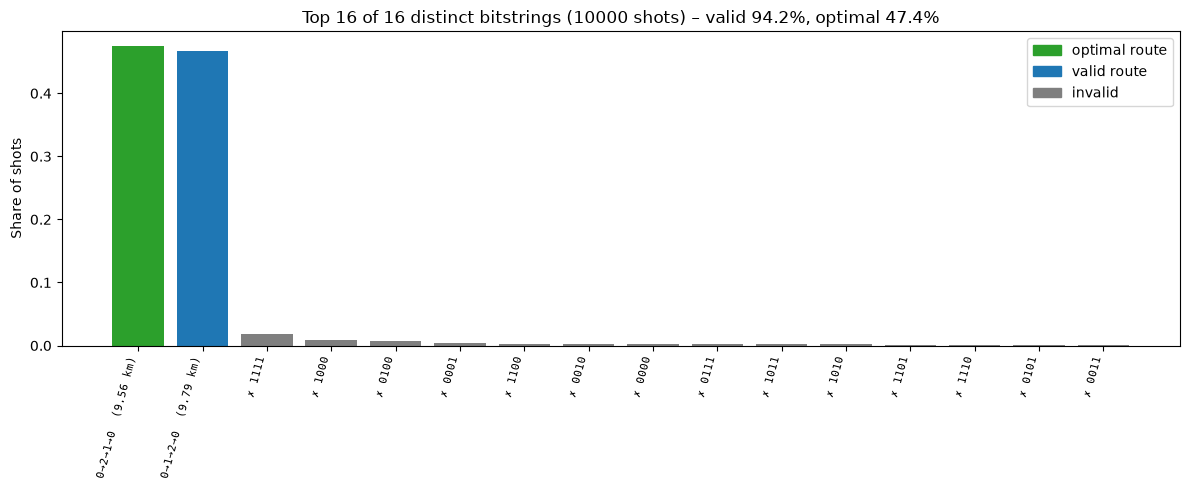

── cluster of 2: nodes [2, 9]  [trivial]
   route  2 → 9 → 2   6.242 km   (classical optimum 6.242 km ✓)


In [7]:
cluster_results = {}
for rep in cluster_order:
    cluster = clusters[reps.index(rep)]
    nodes = [rep] + [i for i in cluster if i != rep]       # the representative is the local depot
    res = solve_subproblem(nodes, f"cluster of {rep}")
    cluster_results[rep] = res
    report(res)
    if res.sampled is not None:
        plot_samples(res.sampled, top=20)
        plt.show()

## 6. Final route

The central route with every cluster loop inserted at its representative.
A representative appears twice (arriving at it and returning to it after the loop); the vehicle just drives through it again.

In [8]:
def assemble(central: SubResult, cluster_results: dict[int, SubResult]) -> list[int]:
    route = [central.route[0]]
    for rep in central.route[1:-1]:
        route.extend(cluster_results[rep].route)            # rep → … → rep
    route.append(central.route[-1])
    return route


def length_of(route_ids: list[int], inst: Instance) -> float:
    idx = [inst.ids.index(i) for i in route_ids]
    return float(sum(inst.distances[a, b] for a, b in zip(idx, idx[1:])))


final_route = assemble(central, cluster_results)
final_length = length_of(final_route, inst_all)
parts = [central] + [cluster_results[r] for r in cluster_order]
assert np.isclose(final_length, sum(p.length for p in parts)), "route length must equal the sum of its parts"
print("Final route:", " → ".join(map(str, final_route)))
print(f"Length:      {final_length:.3f} km  (= central {central.length:.3f} + clusters "
      f"{' + '.join(f'{cluster_results[r].length:.3f}' for r in cluster_order)})")

Final route: 0 → 1 → 3 → 4 → 5 → 1 → 6 → 8 → 7 → 6 → 2 → 9 → 2 → 0
Length:      52.839 km  (= central 26.931 + clusters 10.109 + 9.557 + 6.242)


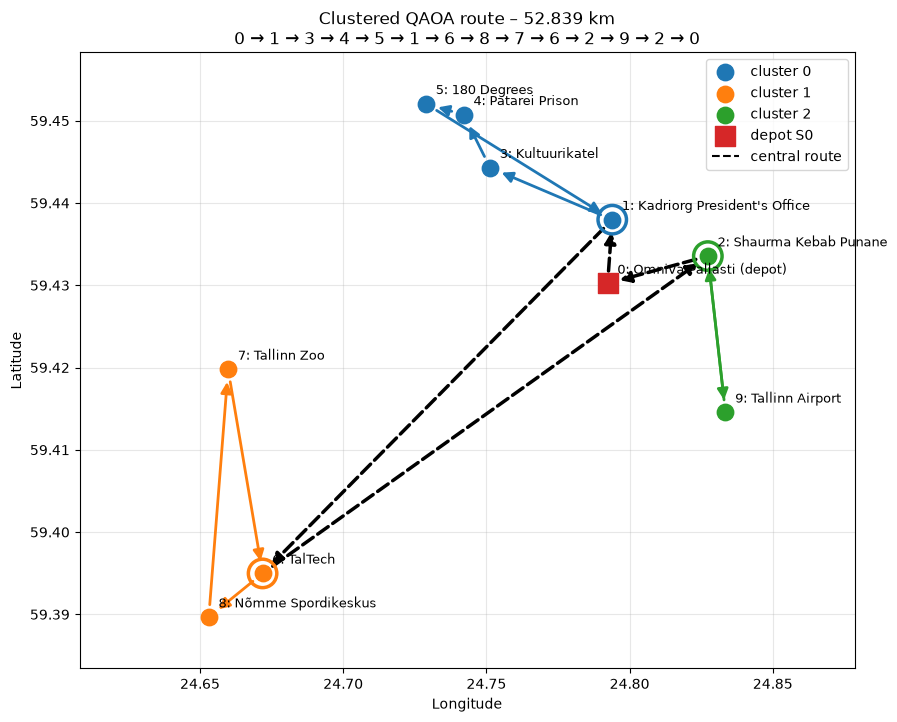

In [9]:
def plot_final_route(inst: Instance, route_ids: list[int], clusters: list[list[int]], reps: list[int], title: str):
    """Arrows show the direction of travel (it matters for asymmetric distances)."""
    colors = plt.cm.tab10.colors
    cluster_of = {i: k for k, c in enumerate(clusters) for i in c}
    fig, ax = plt.subplots(figsize=(10, 8))
    for a, b in zip(route_ids, route_ids[1:]):
        if a == b:
            continue
        ia, ib = inst.ids.index(a), inst.ids.index(b)
        same_cluster = a in cluster_of and b in cluster_of and cluster_of[a] == cluster_of[b]
        ax.annotate("", xy=(inst.lon[ib], inst.lat[ib]), xytext=(inst.lon[ia], inst.lat[ia]),
                    arrowprops=dict(arrowstyle="-|>", lw=2 if same_cluster else 2.5, mutation_scale=16,
                                    color=colors[cluster_of[a]] if same_cluster else "black",
                                    linestyle="-" if same_cluster else "--", shrinkA=9, shrinkB=9))
    for k, cluster in enumerate(clusters):
        idx = [inst.ids.index(i) for i in cluster]
        ax.scatter(inst.lon[idx], inst.lat[idx], s=140, color=colors[k], label=f"cluster {k}", zorder=3)
        r = inst.ids.index(reps[k])
        ax.scatter(inst.lon[r], inst.lat[r], s=420, facecolors="none", edgecolors=colors[k], linewidths=2.5, zorder=3)
    ax.scatter(inst.lon[0], inst.lat[0], s=200, c="tab:red", marker="s", label="depot S0", zorder=4)
    for i, name in enumerate(inst.names):
        ax.annotate(f"{inst.ids[i]}: {name}", (inst.lon[i], inst.lat[i]), xytext=(7, 7),
                    textcoords="offset points", fontsize=9)
    ax.plot([], [], "k--", label="central route")
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    ax.margins(x=0.25, y=0.1)
    return fig


plot_final_route(inst_all, final_route, clusters, reps,
                 f"Clustered QAOA route – {final_length:.3f} km\n{' → '.join(map(str, final_route))}")
plt.show()

## 7. Comparison with classical solutions

- **Pipeline, classical parts** – the same decomposition, but every sub-problem solved exactly (brute force).
  The gap to QAOA shows what QAOA loses on the sub-problems.
- **Global optimum** – brute force over all 9! = 362 880 routes through all locations.
  The gap to the pipeline shows what the **decomposition itself** costs (fixed cluster order, closed loops, representatives).

In [10]:
classical_parts = central.optimal_length + sum(cluster_results[r].optimal_length for r in cluster_order)
global_routes, global_length = brute_force(inst_all.distances)
global_route = [inst_all.ids[i] for i in global_routes[0]]

print(f"{'Global optimum (brute force)':34s} {global_length:8.3f} km   {' → '.join(map(str, global_route))}")
print(f"{'Pipeline, classical sub-problems':34s} {classical_parts:8.3f} km   (+{classical_parts / global_length - 1:.1%})")
print(f"{'Pipeline, QAOA sub-problems':34s} {final_length:8.3f} km   (+{final_length / global_length - 1:.1%})")
print()
for p in parts:
    print(f"  {p.label:22s} {p.method:18s} {p.length:7.3f} km  (optimum {p.optimal_length:7.3f}) "
          f"{'✓' if p.is_optimal else '✗'}")

Global optimum (brute force)         40.303 km   0 → 1 → 3 → 4 → 5 → 7 → 8 → 6 → 9 → 2 → 0
Pipeline, classical sub-problems     52.839 km   (+31.1%)
Pipeline, QAOA sub-problems          52.839 km   (+31.1%)

  central graph          QAOA                26.931 km  (optimum  26.931) ✓
  cluster of 1           QAOA                10.109 km  (optimum  10.109) ✓
  cluster of 6           QAOA                 9.557 km  (optimum   9.557) ✓
  cluster of 2           trivial              6.242 km  (optimum   6.242) ✓
